# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [2]:
SOURCE_URL = [
    "https://fred.stlouisfed.org/series/FPICA",
    "https://fred.stlouisfed.org/series/FEDFUNDS",
    "https://fred.stlouisfed.org/series/A191RL1A225NBEA",
    "https://fred.stlouisfed.org/series/FPCPITOTLZGUSA"
]

DOWNLOAD_DATE = {
    "FPICA": "2026-11-08",
    "FEDFUNDS": "ENTER ORIGINAL DOWNLOAD DATE",
    "A191RL1A225NBEA": "ENTER ORIGINAL DOWNLOAD DATE",
    "FPCPITOTLZGUSA": "ENTER ORIGINAL DOWNLOAD DATE"
}

FILE_NAME = [
    "FPICA.csv",
    "FEDFUNDS.csv",
    "A191RL1A225NBEA.csv",
    "FPCPITOTLZGUSA.csv"
]


In [3]:
# Load datasets
investment = pd.read_csv("data/FPICA.csv")
interest = pd.read_csv("data/FEDFUNDS.csv")
gdp = pd.read_csv("data/A191RL1A225NBEA.csv")
inflation = pd.read_csv("data/FPCPITOTLZGUSA.csv")

# Convert dates and extract year
for data in [investment, interest, gdp, inflation]:
    data["observation_date"] = pd.to_datetime(data["observation_date"])
    data["year"] = data["observation_date"].dt.year

# Check source coverage and missing values
for name, data, column in [
    ("Real private fixed investment", investment, "FPICA"),
    ("Federal funds rate", interest, "FEDFUNDS"),
    ("Real GDP growth", gdp, "A191RL1A225NBEA"),
    ("Inflation", inflation, "FPCPITOTLZGUSA"),
]:
    print(
        f"{name}: {len(data)} rows; "
        f"{data['year'].min()}–{data['year'].max()}; "
        f"{data[column].isna().sum()} missing values"
    )

# Calculate annual average interest rates
interest = interest.groupby("year", as_index=False)["FEDFUNDS"].mean()

# Calculate real investment growth
investment = investment.sort_values("observation_date")
investment["investment_growth"] = (
    investment["FPICA"].pct_change(fill_method=None) * 100
)

# Merge annual datasets
df = (
    investment[["year", "investment_growth"]]
    .merge(interest, on="year")
    .merge(gdp[["year", "A191RL1A225NBEA"]], on="year")
    .merge(inflation[["year", "FPCPITOTLZGUSA"]], on="year")
)

df = df.rename(columns={
    "FEDFUNDS": "interest_rate",
    "A191RL1A225NBEA": "gdp_growth",
    "FPCPITOTLZGUSA": "inflation"
})

# Use years with complete data
df = (
    df[df["year"].between(1968, 2024)]
    .dropna()
    .reset_index(drop=True)
)

print("\nFinal observations:", len(df))
print("Study period:", df["year"].min(), "to", df["year"].max())
print("\nMissing values:")
print(df.isna().sum())

display(df.head())

Real private fixed investment: 59 rows; 1967–2025; 0 missing values
Federal funds rate: 868 rows; 1954–2026; 0 missing values
Real GDP growth: 96 rows; 1930–2025; 0 missing values
Inflation: 65 rows; 1960–2024; 0 missing values

Final observations: 57
Study period: 1968 to 2024

Missing values:
year                 0
investment_growth    0
interest_rate        0
gdp_growth           0
inflation            0
dtype: int64


,year,investment_growth,interest_rate,gdp_growth,inflation
0,1968,7.024311,5.659167,4.9,4.271796
1,1969,5.905520,8.204167,3.1,5.462386
2,1970,-2.051037,7.183333,0.2,5.838255
3,1971,6.866857,4.662500,3.3,4.292767
4,1972,11.402239,4.434167,5.3,3.272278


**Who collected it, for what purpose, what is missing and why?**

The data were downloaded from FRED, maintained by the Federal Reserve Bank of St. Louis. The investment outcome uses the Bureau of Economic Analysis’s annual Real Private Fixed Investment series (FPICA), measured in billions of chained dollars. I calculate its annual percentage growth to measure changes in inflation-adjusted private fixed investment.

The federal funds rate is the main explanatory variable, while real GDP growth and inflation are controls. Monthly federal funds rates are converted to annual averages.

The analysis uses the common study period, 1960–2024. Source coverage and missing values are checked before merging, and missing values are checked again in the final sample. Excluding years outside the shared coverage is a coverage limitation rather than evidence that missingness is random.

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

How is the annual average federal funds rate associated with annual real private fixed investment growth in the United States from 1960–2024, controlling for real GDP growth and inflation?

This question matters to businesses planning investment and policymakers assessing economic conditions because interest rates influence borrowing costs.

The outcome is annual real private fixed investment growth. The federal funds rate is the main explanatory variable; real GDP growth and inflation are controls. Each observation represents one U.S. year.

Investment growth is calculated as the annual percentage change in an inflation-adjusted investment series. Monthly federal funds rates are averaged within each year. The analysis examines associations rather than identifying a causal effect.

In [4]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "U.S. year"
OUTCOME = "investment_growth"
MAIN_X = "interest_rate"
CONTROLS = ["gdp_growth", "inflation"]


if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 57   Columns: 5   One row is: U.S. year

Missing values per column:
investment_growth    0
interest_rate        0
gdp_growth           0
inflation            0

Skew of investment_growth: -0.91 (above about 1, consider a log)


In [5]:
# Verify the final dataset
print("Dataset shape:", df.shape)
print("Years:", df["year"].min(), "-", df["year"].max())

print("\nMissing values:")
print(df.isna().sum())

print("\nSummary statistics:")
display(
    df[[
        "investment_growth",
        "interest_rate",
        "inflation",
        "gdp_growth"
    ]].describe().round(2)
)


Dataset shape: (57, 5)
Years: 1968 - 2024

Missing values:
year                 0
investment_growth    0
interest_rate        0
gdp_growth           0
inflation            0
dtype: int64

Summary statistics:


,investment_growth,interest_rate,inflation,gdp_growth
count,57.00,57.00,57.00,57.00
mean,3.84,4.98,4.05,2.80
std,5.98,3.77,2.80,2.02
min,-15.99,0.08,-0.36,-2.60
25%,1.81,1.68,2.27,2.00
50%,5.14,5.02,3.23,2.90
75%,7.41,7.18,4.83,4.10
max,16.19,16.38,13.55,7.20


### Data Completeness and Missingness

The final dataset contains annual U.S. observations from 1960 through 2024. I combined the FRED series using their common years and checked for missing values.

The final dataset has no missing values in the four regression variables. However, restricting the sample to overlapping years may exclude periods where some series are unavailable. This is a data-availability limitation rather than evidence that the original sources were completely observed.

Because there are no missing values within the final sample, MCAR, MAR, and MNAR cannot be reliably distinguished from the merged dataset alone.

**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?

*Answers:*

1. **Controls:** Inflation and real GDP growth may influence both interest rates and investment decisions. However, interest rates can also affect both controls. Conditioning on them may therefore remove part of the relationship being studied. V1 describes the unconditional association, V2 conditions on inflation, and V3 additionally conditions on GDP growth. None establishes a causal effect.

2. **Units:** All observations represent U.S. years from 1968–2024. Investment growth, GDP growth, and inflation are annual percentage rates. The federal funds rate is an annual average interest rate expressed as a percentage. Coefficient interpretations use percentage-point changes.

3. **Policy:** This study does not evaluate a specific policy change, so a before-and-after comparison is not required.

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

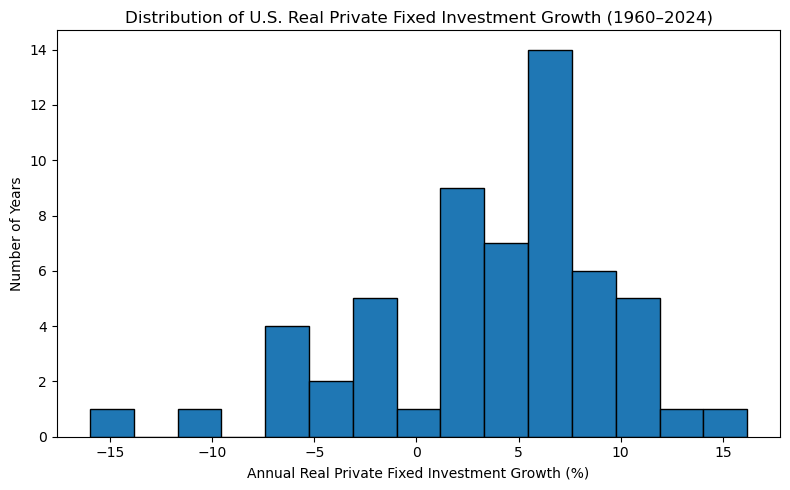

In [6]:
# Figure 1: Distribution of investment growth
plt.figure(figsize=(8, 5))

plt.hist(df["investment_growth"], bins=15, edgecolor="black")

plt.xlabel("Annual Real Private Fixed Investment Growth (%)")
plt.ylabel("Number of Years")
plt.title("Distribution of U.S. Real Private Fixed Investment Growth (1960–2024)")

plt.tight_layout()
plt.show()


I am looking for whether investment growth is concentrated around typical values or has extreme observations. This helps us decide whether OLS is reasonable and whether a transformation might be useful.

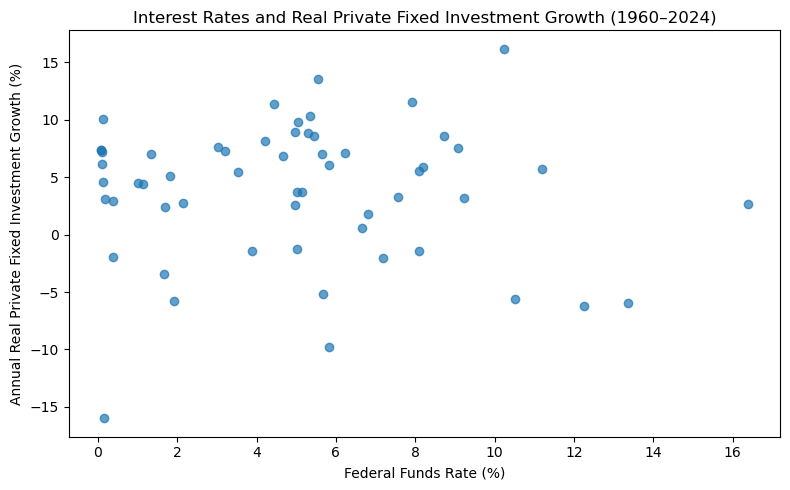

In [7]:
# Figure 2: Interest rates and investment growth
plt.figure(figsize=(8, 5))

plt.scatter(df["interest_rate"], df["investment_growth"], alpha=0.7)

plt.xlabel("Federal Funds Rate (%)")
plt.ylabel("Annual Real Private Fixed Investment Growth (%)")
plt.title("Interest Rates and Real Private Fixed Investment Growth (1960–2024)")

plt.tight_layout()
plt.show()


This scatter plot is important because it related to my question and shows whether years with higher interest rates generally have lower investment growth

**Figure 1:** Annual real private fixed investment growth is concentrated around positive values, with several unusually low-growth years. The distribution is left-skewed (skewness = −0.91). I retain the growth-rate scale because an ordinary logarithm would be undefined for negative growth observations.

**Figure 2:** The scatterplot shows substantial dispersion and little apparent linear association between interest rates and real private fixed investment growth. It does not account for inflation or GDP growth and does not establish causation.

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [8]:
# Relationship between interest rates and investment growth

model_v1 = smf.ols(
    "investment_growth ~ interest_rate",
    data=df
).fit()

# Create regression table
results_v1 = pd.DataFrame({
    "Coefficient": model_v1.params,
    "Std. Error": model_v1.bse,
    "P-value": model_v1.pvalues
})

# Add model statistics
results_v1.loc["Observations"] = [int(model_v1.nobs), np.nan, np.nan]
results_v1.loc["R-squared"] = [model_v1.rsquared, np.nan, np.nan]

display(results_v1.round(3))


,Coefficient,Std. Error,P-value
Intercept,4.222,1.331,0.002
interest_rate,-0.076,0.214,0.723
Observations,57.000,NaN,NaN
R-squared,0.002,NaN,NaN


In [9]:
# Adding inflation to model

model_v2 = smf.ols(
    "investment_growth ~ interest_rate + inflation",
    data=df
).fit()

# Create regression table
results_v2 = pd.DataFrame({
    "Coefficient": model_v2.params,
    "Std. Error": model_v2.bse,
    "P-value": model_v2.pvalues
})

# Add model statistics
results_v2.loc["Observations"] = [int(model_v2.nobs), np.nan, np.nan]
results_v2.loc["R-squared"] = [model_v2.rsquared, np.nan, np.nan]

display(results_v2.round(3))


,Coefficient,Std. Error,P-value
Intercept,4.972,1.439,0.001
interest_rate,0.214,0.306,0.486
inflation,-0.543,0.412,0.192
Observations,57.000,NaN,NaN
R-squared,0.034,NaN,NaN


In [10]:
# Compare Version 1 and Version 2
comparison = pd.DataFrame({
    "Version 1": [
        model_v1.params["interest_rate"],
        model_v1.pvalues["interest_rate"],
        model_v1.rsquared
    ],
    "Version 2": [
        model_v2.params["interest_rate"],
        model_v2.pvalues["interest_rate"],
        model_v2.rsquared
    ]
}, index=[
    "Interest Rate Coefficient",
    "Interest Rate P-value",
    "R-squared"
])

display(comparison.round(3))


,Version 1,Version 2
Interest Rate Coefficient,-0.076,0.214
Interest Rate P-value,0.723,0.486
R-squared,0.002,0.034


### Version 2: Adding Inflation

I included inflation as a potential confounder because it may influence both monetary policy and real investment decisions. However, interest rates can also affect inflation, making contemporaneous inflation a potentially problematic control.

After adding inflation, the interest-rate coefficient changes from −0.076 to +0.214. Its p-value changes from 0.723 to 0.486, and R-squared increases from 0.002 to 0.034. The interest-rate coefficient is not statistically significant at the 5% level in either model.

V2 describes an association conditional on inflation rather than a total causal effect. It does not yet account for overall economic growth.

In [11]:
#Adding real GDP growth to the model
model_v3 = smf.ols(
    "investment_growth ~ interest_rate + inflation + gdp_growth",
    data=df
).fit()

# Create regression table
results_v3 = pd.DataFrame({
    "Coefficient": model_v3.params,
    "Std. Error": model_v3.bse,
    "P-value": model_v3.pvalues
})

# Add model statistics
results_v3.loc["Observations"] = [int(model_v3.nobs), np.nan, np.nan]
results_v3.loc["R-squared"] = [model_v3.rsquared, np.nan, np.nan]

display(results_v3.round(3))


,Coefficient,Std. Error,P-value
Intercept,-2.477,0.922,0.010
interest_rate,-0.196,0.156,0.214
inflation,0.006,0.209,0.976
gdp_growth,2.596,0.202,0.000
Observations,57.000,NaN,NaN
R-squared,0.765,NaN,NaN


In [12]:
# Compare all three model versions
comparison = pd.DataFrame({
    "Version 1": [
        model_v1.params["interest_rate"],
        model_v1.pvalues["interest_rate"],
        model_v1.rsquared
    ],
    "Version 2": [
        model_v2.params["interest_rate"],
        model_v2.pvalues["interest_rate"],
        model_v2.rsquared
    ],
    "Version 3": [
        model_v3.params["interest_rate"],
        model_v3.pvalues["interest_rate"],
        model_v3.rsquared
    ]
}, index=[
    "Interest Rate Coefficient",
    "Interest Rate P-value",
    "R-squared"
])

display(comparison.round(3))


,Version 1,Version 2,Version 3
Interest Rate Coefficient,-0.076,0.214,-0.196
Interest Rate P-value,0.723,0.486,0.214
R-squared,0.002,0.034,0.765


### Version 3: Adding Real GDP Growth

I added real GDP growth to account for broader economic activity that may influence both interest rates and investment growth.

The interest-rate coefficient changes from +0.214 in V2 to −0.196 in V3, while R-squared increases from 0.034 to 0.765. The interest-rate coefficient is not statistically significant at the 5% level (p = 0.2137).

A one-percentage-point increase in real GDP growth is associated with a 2.596-percentage-point increase in real private fixed investment growth, holding interest rates and inflation constant. This estimate is statistically significant using both conventional and HC3 robust standard errors (p < 0.001).

GDP growth may be a problematic control because investment contributes to GDP and interest rates can affect economic growth. The higher R-squared therefore does not establish that V3 is better for estimating a causal relationship.

### Interest Rate Coefficient

In V3, a one-percentage-point increase in the annual average federal funds rate is associated with a 0.196-percentage-point decrease in annual real private fixed investment growth, holding inflation and real GDP growth constant.

The conventional standard error is 0.1556, with p = 0.2137. Using HC3 robust standard errors increases the standard error to 0.2137 and the p-value to 0.3635.

The estimate is negative, but the evidence is insufficient to establish a negative conditional association at the 5% level. This does not demonstrate that the true relationship is zero.

### Table 1. OLS Models of Annual U.S. Real Private Fixed Investment Growth (1968–2024)

*Dependent variable: Annual real private fixed investment growth (%).*

Coefficients are reported with conventional OLS standard errors in parentheses. All models use 57 annual observations. V1 includes only the federal funds rate; V2 adds inflation; V3 additionally includes real GDP growth. HC3 robust standard errors for V3 are reported separately in Section 4.

In [13]:
# Formatted regression comparison table
models = {
    "V1: Baseline": model_v1,
    "V2: + Inflation": model_v2,
    "V3: + GDP Growth": model_v3
}

table = pd.DataFrame()

for name, model in models.items():
    table[name] = [
        f"{model.params[v]:.3f} ({model.bse[v]:.3f})"
        if v in model.params else "—"
        for v in ["Intercept", "interest_rate", "inflation", "gdp_growth"]
    ]

table.index = [
    "Intercept",
    "Federal Funds Rate",
    "Inflation",
    "Real GDP Growth"
]

table.loc["Observations"] = [
    int(model.nobs) for model in models.values()
]

table.loc["R-squared"] = [
    f"{model.rsquared:.3f}" for model in models.values()
]

display(table)

,V1: Baseline,V2: + Inflation,V3: + GDP Growth
Intercept,4.222 (1.331),4.972 (1.439),-2.477 (0.922)
Federal Funds Rate,-0.076 (0.214),0.214 (0.306),-0.196 (0.156)
Inflation,—,-0.543 (0.412),0.006 (0.209)
Real GDP Growth,—,—,2.596 (0.202)
Observations,57,57,57
R-squared,0.002,0.034,0.765


### Model Comparison

The interest-rate coefficient changes across specifications: −0.076 in V1, +0.214 in V2, and −0.196 in V3. It is not statistically significant at the 5% level in any version.

R-squared increases from 0.002 in V1 to 0.034 in V2 and 0.765 in V3. Adding GDP growth substantially increases the variation explained within this sample.

However, contemporaneous inflation and GDP growth may respond to interest rates, and investment contributes to GDP. The comparisons show sensitivity to control choices rather than establishing a causal effect.

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

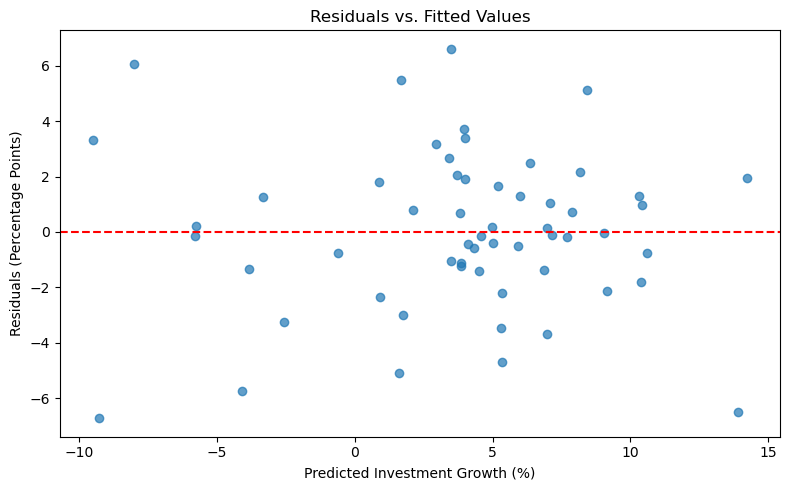

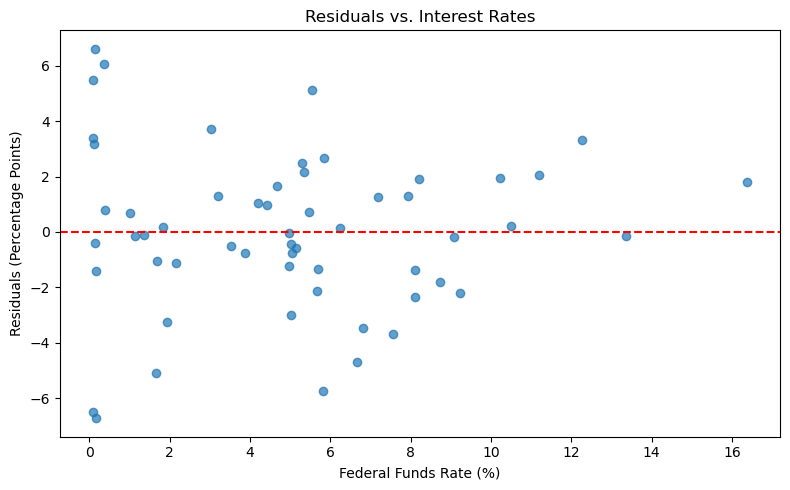

In [14]:
# Section 4: Residual diagnostics for Version 3

# Get predicted values and residuals
fitted = model_v3.fittedvalues
residuals = model_v3.resid

# Residuals vs. fitted values
plt.figure(figsize=(8, 5))
plt.scatter(fitted, residuals, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Investment Growth (%)")
plt.ylabel("Residuals (Percentage Points)")
plt.title("Residuals vs. Fitted Values")

plt.tight_layout()
plt.show()

# Residuals vs. interest rates
plt.figure(figsize=(8, 5))
plt.scatter(df["interest_rate"], residuals, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Federal Funds Rate (%)")
plt.ylabel("Residuals (Percentage Points)")
plt.title("Residuals vs. Interest Rates")

plt.tight_layout()
plt.show()


### Residual Diagnostics

I examined residual plots against fitted values and interest rates. Both plots show residuals scattered around zero without a clear curved pattern, suggesting the linear specification is reasonable.

However, there are some large residuals and uneven variation across observations. I will use a formal test to check for heteroskedasticity and examine whether any observations have a strong influence on the model.

In [15]:

# Breusch-Pagan test for heteroskedasticity
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(
    model_v3.resid,
    model_v3.model.exog
)

print("Breusch-Pagan Test")
print("LM Statistic:", round(bp_test[0], 3))
print("P-value:", round(bp_test[1], 4))


Breusch-Pagan Test
LM Statistic: 10.708
P-value: 0.0134


### Heteroskedasticity Test

The Breusch–Pagan test produced an LM statistic of 10.708 and a p-value of 0.0134.

I reject the null hypothesis of constant variance at the 5% significance level. This provides evidence of heteroskedasticity, so I use HC3 robust standard errors to assess the precision of the V3 estimates.

In [16]:
# Calculate HC3 robust standard errors
model_robust = model_v3.get_robustcov_results(cov_type="HC3")

# Compare original and robust standard errors
se_comparison = pd.DataFrame({
    "Original SE": model_v3.bse,
    "Robust SE (HC3)": model_robust.bse,
    "Original P-value": model_v3.pvalues,
    "Robust P-value": model_robust.pvalues
}, index=model_v3.params.index)

display(se_comparison.round(4))


,Original SE,Robust SE (HC3),Original P-value,Robust P-value
Intercept,0.9222,1.5960,0.0096,0.1266
interest_rate,0.1556,0.2137,0.2137,0.3635
inflation,0.2094,0.2848,0.9762,0.9825
gdp_growth,0.2023,0.3518,0.0000,0.0000


### Robust Standard Errors

HC3 robust standard errors are larger than the conventional standard errors for all V3 coefficients.

For the interest-rate coefficient, the standard error increases from 0.1556 to 0.2137, and the p-value increases from 0.2137 to 0.3635. The estimate remains statistically insignificant at the 5% level.

GDP growth remains statistically significant (p < 0.001), while inflation is not significant (HC3 p = 0.9825). HC3 adjusts inference for heteroskedasticity but does not address serial correlation or establish causality.

In [17]:
# Check multicollinearity using VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Get explanatory variables from Version 3
X = model_v3.model.exog
names = model_v3.model.exog_names

# Calculate VIF for each variable
vif = pd.DataFrame({
    "Variable": names,
    "VIF": [
        variance_inflation_factor(X, i)
        for i in range(X.shape[1])
    ]
})

# Exclude intercept from interpretation
vif = vif[vif["Variable"] != "Intercept"]

display(vif.round(2))


,Variable,VIF
1,interest_rate,2.17
2,inflation,2.16
3,gdp_growth,1.05


### Multicollinearity Check

The VIF values are 2.17 for interest rates, 2.16 for inflation, and 1.05 for GDP growth.

These values are below the common screening threshold of 5, suggesting that severe multicollinearity is not a major concern. VIF does not determine whether a control is appropriate for causal interpretation.

In [18]:
# Check influential observations using Cook's distance
influence = model_v3.get_influence()
cooks_d = influence.cooks_distance[0]

# Add Cook's distance to the dataset
df_influence = df.copy()
df_influence["cooks_distance"] = cooks_d

# Screening threshold
threshold = 4 / len(df)

print("Cook's distance threshold:", round(threshold, 4))

# Show observations above the threshold
influential = df_influence[
    df_influence["cooks_distance"] > threshold
]

display(
    influential[["year", "cooks_distance"]]
    .sort_values("cooks_distance", ascending=False)
    .round(4)
)


Cook's distance threshold: 0.0702


,year,cooks_distance
41,2009,0.4136
53,2021,0.3389
52,2020,0.2139
7,1975,0.1745
14,1982,0.1206


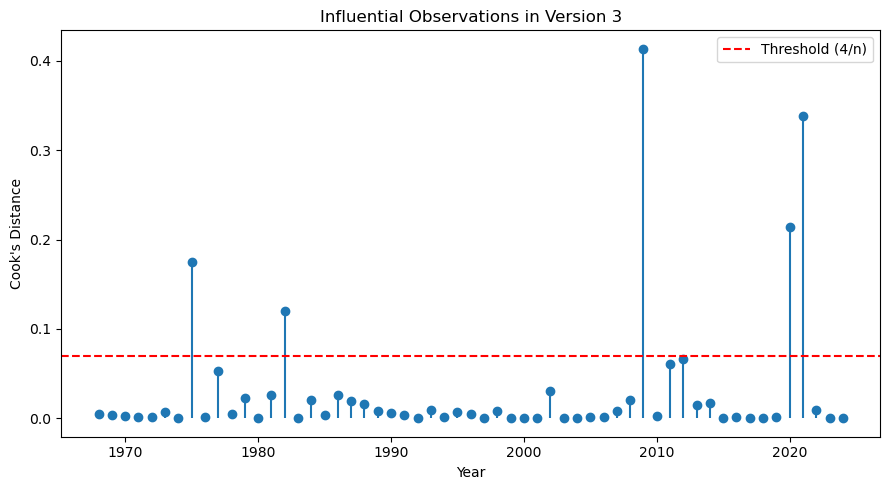

In [19]:
# Plot Cook's distance by year
plt.figure(figsize=(9, 5))

plt.stem(
    df_influence["year"],
    df_influence["cooks_distance"],
    basefmt=" "
)

plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="Threshold (4/n)"
)

plt.xlabel("Year")
plt.ylabel("Cook's Distance")
plt.title("Influential Observations in Version 3")
plt.legend()

plt.tight_layout()
plt.show()


### Influential Observations

Five years exceed the Cook’s distance screening threshold of 0.0702: 1975, 1982, 2009, 2020, and 2021.

The largest Cook’s distances are 2009 (0.4136), 2021 (0.3389), and 2020 (0.2139). These observations may have substantial influence on the fitted model.

I retain these years because they represent real economic conditions. Exceeding the screening threshold does not, by itself, justify removing an observation.

### Overall Diagnostic Findings

The residual plots do not reveal a clear curved pattern, but this does not establish that all model assumptions hold.

The Breusch–Pagan test provides evidence of heteroskedasticity (p = 0.0134). HC3 robust standard errors increase uncertainty around the interest-rate estimate, which remains statistically insignificant at the 5% level.

VIF values suggest that severe multicollinearity is not a major concern. Cook’s distance identifies five potentially influential years.

These findings support cautious interpretation of V3 as a model of conditional associations.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

### Threats to Interpretation

This analysis examines the association between the federal funds rate and annual real private fixed investment growth in the United States from 1968–2024.

A causal interpretation would require interest rates to be unrelated to unobserved determinants of investment growth after conditioning on appropriate controls. This analysis does not establish that condition. The Federal Reserve responds to economic conditions, and omitted factors such as credit availability and business confidence may influence both rates and investment.

Inflation and GDP growth may also respond to interest rates. Controlling for them could remove part of the relationship being studied, while investment’s contribution to GDP creates an additional interpretation problem.

The diagnostics identify heteroskedasticity and potentially influential years. Annual errors may also be correlated across time, which HC3 robust standard errors do not address.

The estimates should therefore be interpreted as conditional associations rather than causal effects.

### Conclusion

Using 57 annual observations from 1968–2024, V3 estimates that a one-percentage-point increase in the federal funds rate is associated with a 0.196-percentage-point decrease in real private fixed investment growth, holding inflation and real GDP growth constant.

The estimate is not statistically significant at the 5% level using either conventional errors (p = 0.2137) or HC3 robust errors (p = 0.3635). The analysis therefore provides insufficient evidence of a negative conditional association, rather than demonstrating that interest rates have no effect.

With another month, I would investigate lagged interest rates, additional confounders, and serial correlation.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

### Appendix: Data and Model Details

**Sample:** 57 annual U.S. observations from 1968–2024.

**Variables:**

- `investment_growth`: Annual percentage growth in real private fixed investment, calculated from FRED series FPICA.
- `interest_rate`: Annual average federal funds rate (%), the main explanatory variable.
- `inflation`: Annual inflation rate (%), a control.
- `gdp_growth`: Annual real GDP growth (%), a control.

**Model specifications:**

- **V1:** Investment growth regressed on the federal funds rate.
- **V2:** Adds inflation.
- **V3:** Adds real GDP growth.

All models use OLS. V3 is the most comprehensive specification, but its controls do not establish causal identification.

**Diagnostics:** Residual plots, the Breusch–Pagan test, HC3 robust standard errors, VIF, and Cook’s distance.

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [21]:
REPORT_NUMBERS = {
    # Section 1: Data
    "Section 1: observations": len(df),
    "Section 1: first year": int(df["year"].min()),
    "Section 1: last year": int(df["year"].max()),

    # Section 3: Model comparison
    "Section 3: V1 R-squared": round(model_v1.rsquared, 3),
    "Section 3: V2 R-squared": round(model_v2.rsquared, 3),
    "Section 3: V3 R-squared": round(model_v3.rsquared, 3),

    "Section 3: V1 interest rate coefficient":
        round(model_v1.params["interest_rate"], 3),
    "Section 3: V2 interest rate coefficient":
        round(model_v2.params["interest_rate"], 3),
    "Section 3: V3 interest rate coefficient":
        round(model_v3.params["interest_rate"], 3),

    "Section 3: V3 interest rate p-value":
        round(model_v3.pvalues["interest_rate"], 4),
    "Section 3: V3 GDP growth coefficient":
        round(model_v3.params["gdp_growth"], 3),
    "Section 3: V3 inflation coefficient":
        round(model_v3.params["inflation"], 3),

    # Section 4: Diagnostics
    "Section 4: Breusch-Pagan LM statistic":
        round(bp_test[0], 3),
    "Section 4: Breusch-Pagan p-value":
        round(bp_test[1], 4),

    "Section 4: HC3 interest rate p-value":
        round(model_robust.pvalues[
            list(model_v3.params.index).index("interest_rate")
        ], 4),

    "Section 4: Cook's distance threshold":
        round(threshold, 4),
    "Section 4: influential observations":
        len(influential),
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")


Section 1: observations: 57
Section 1: first year: 1968
Section 1: last year: 2024
Section 3: V1 R-squared: 0.002
Section 3: V2 R-squared: 0.034
Section 3: V3 R-squared: 0.765
Section 3: V1 interest rate coefficient: -0.076
Section 3: V2 interest rate coefficient: 0.214
Section 3: V3 interest rate coefficient: -0.196
Section 3: V3 interest rate p-value: 0.2137
Section 3: V3 GDP growth coefficient: 2.596
Section 3: V3 inflation coefficient: 0.006
Section 4: Breusch-Pagan LM statistic: 10.708
Section 4: Breusch-Pagan p-value: 0.0134
Section 4: HC3 interest rate p-value: 0.3635
Section 4: Cook's distance threshold: 0.0702
Section 4: influential observations: 5
